# Qualcomm — FY2029 SOTP valuation

Valued **November 21, 2026**, on **Q4 / full-year FY2026** actuals reported November 4.
Price anchor: **$149.94**, November 20 regular-session close.

`model.py` owns all assumptions and valuation calculations. This notebook imports it,
keeps full precision in calculations, and rounds only for display. See README for
source links, the target-mapping correction, and revision history. Not investment advice.

In [1]:
import importlib
import model
m = importlib.reload(model)
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SEGMENTS = m.SEGMENTS
SEG_COLORS = {'handset': '#2a78d6', 'automotive': '#eb6834', 'iot': '#1baf7a', 'datacenter': '#eda100'}
SCEN_COLORS = {'Bear': '#d03b3b', 'Base': '#6b6b66', 'Bull': '#2a78d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
                     'figure.facecolor': 'white'})
print(m.VALUATION_DATE, '|', m.LATEST_REPORT)
print(f'Price ${m.CURRENT_PRICE:.2f} ({m.PRICE_DATE}); shares {m.SHARES_OUT:.3f}B; '
      f'net debt ${m.NET_DEBT:.3f}B; horizon {m.YEARS_TO_FY29:.4f} years')


November 21, 2026 | Q4 / FY2026 — year ended September 27, 2026, reported November 4, 2026
Price $149.94 (November 20, 2026); shares 1.073B; net debt $7.431B; horizon 2.8583 years


## 1. Assumptions and target mapping

Management targets $40B QCT non-handset revenue and approximately one-third QCT
handset mix. This implies ~$20B handset chips **before licensing**. We assume QTL
stays at FY26's $5.556B. Automotive is $10B; the remaining $30B is allocated to IoT
and data center in a 14:15 ratio, an explicit author allocation consistent with the
stated >$14B and >$15B thresholds. Base total revenue is $65.556B.

The prior model incorrectly included licensing in $20B and summed non-handset to
$39B. Margins and multiples remain author assumptions. Bear auto revenue moves
$8B→$9B, IoT $10B→$9B, and handset margin 32%→30%. Weights remain 25/50/25.

In [2]:
assumptions = pd.concat({s: pd.DataFrame({
    'revenue $B': m.REVENUE[s], 'EBITDA margin': m.EBITDA_MARGIN[s],
    'exit multiple': m.EXIT_MULTIPLE[s]}) for s in m.WEIGHTS})
assumptions.round(3)

revenue $B  EBITDA margin  exit multiple
Bear handset         21.556           0.30              7
     automotive       9.000           0.22             10
     iot              9.000           0.24             10
     datacenter       9.000           0.18             11
Base handset         25.556           0.38              8
     automotive      10.000           0.28             13
     iot             14.483           0.30             13
     datacenter      15.517           0.25             18
Bull handset         28.556           0.40             10
     automotive      13.000           0.30             16
     iot             16.000           0.33             18
     datacenter      20.000           0.30             25

## 2. Completed FY2026 and next-quarter guidance

All four FY26 quarters below are actuals. Annual totals use the release's
as-reported figures; individual segment quarter sums can differ by up to $2M from rounding.
The trailing EBITDA measure retains the earlier corporate/D&A bridge and is a
**model proxy**, not a reported or fully reconciled EBITDA figure.
Q1 FY27 guidance is separate and is never presented as a full-year forecast.

In [3]:
q = pd.DataFrame.from_dict(m.FY26_QUARTERS, orient='index',
    columns=['total','qct','qct_ebt','qtl','qtl_ebt','handset','automotive','iot'])
print('FY26 quarterly actuals ($M)')
print(q.to_string())
fy26 = m.fy26_actuals()
print(f"\nFY26 GAAP revenue ${fy26['revenue']:.3f}B; EBITDA proxy ${fy26['ebitda']:.3f}B")
print(f'FY25 GAAP revenue ${m.FY25_REVENUE:.3f}B; EBITDA proxy ${m.FY25_EBITDA:.3f}B')
print('\nQ1 FY27 guidance midpoints only ($B, except EPS):')
print(pd.DataFrame(m.FY27_QUARTERS).T.to_string())
print('Guidance ranges: revenue $10.4–11.2B; QCT $9.0–9.6B; QTL $1.3–1.5B; EPS $2.15–2.35.')
print('Data center: Q1 >$650M; FY27 target $5B. FY27 non-handset growth >60%.')

FY26 quarterly actuals ($M)
    total    qct  qct_ebt   qtl  qtl_ebt  handset  automotive   iot
Q1  12252  10613     3302  1592     1231     7824        1101  1688
Q2  10599   9076     2465  1382      994     6024        1326  1726
Q3   9947   8504     2192  1278      881     5086        1588  1830
Q4  10322   9015     2142  1304      918     5137        1990  1888

FY26 GAAP revenue $43.120B; EBITDA proxy $14.253B
FY25 GAAP revenue $44.284B; EBITDA proxy $15.815B

Q1 FY27 guidance midpoints only ($B, except EPS):
     non_gaap_eps  qct  qct_ebt_margin  qtl  qtl_ebt_margin  revenue
Q1E          2.25  9.3            0.21  1.4            0.74     10.8
Guidance ranges: revenue $10.4–11.2B; QCT $9.0–9.6B; QTL $1.3–1.5B; EPS $2.15–2.35.
Data center: Q1 >$650M; FY27 target $5B. FY27 non-handset growth >60%.


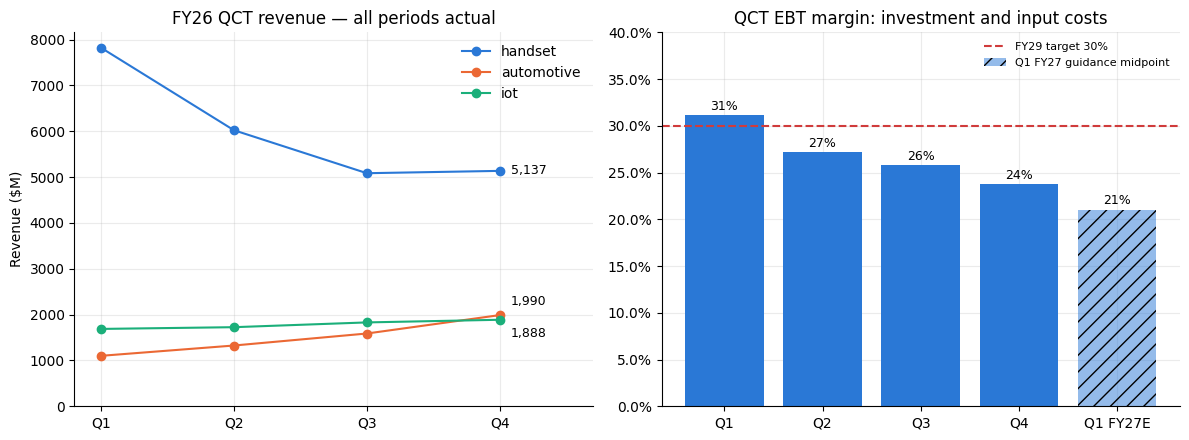

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for s in ['handset','automotive','iot']:
    ax1.plot(range(4), q[s], marker='o', color=SEG_COLORS[s], label=s)
    ax1.annotate(f'{q[s].iloc[-1]:,}', (3, q[s].iloc[-1]), xytext=(8, 10 if s=='automotive' else -10 if s=='iot' else 0),
                 textcoords='offset points', va='center', fontsize=9)
ax1.set_xticks(range(4)); ax1.set_xticklabels(q.index)
ax1.set_xlim(-0.2,3.7); ax1.set_ylim(0,None)
ax1.set_ylabel('Revenue ($M)'); ax1.set_title('FY26 QCT revenue — all periods actual')
ax1.legend(frameon=False)
margins=q.qct_ebt/q.qct*100
bars=ax2.bar(range(4),margins,color=SEG_COLORS['handset'])
ax2.axhline(30,linestyle='--',color='#d03b3b',label='FY29 target 30%')
ax2.bar([4],[m.FY27_QUARTERS['Q1E']['qct_ebt_margin']*100],
        color=SEG_COLORS['handset'],alpha=0.5,hatch='//',label='Q1 FY27 guidance midpoint')
for i,v in enumerate(list(margins)+[21]): ax2.text(i,v+0.6,f'{v:.0f}%',ha='center',fontsize=9)
ax2.set_xticks(range(5)); ax2.set_xticklabels(list(q.index)+['Q1 FY27E'])
ax2.yaxis.set_major_formatter(PercentFormatter(100)); ax2.set_ylim(0,40)
ax2.set_title('QCT EBT margin: investment and input costs')
ax2.legend(frameon=False,fontsize=8,loc='upper right')
fig.tight_layout(); plt.show()

## 3. Run-rate bridge

Growth to FY29 from FY26 year-end uses three fiscal years. The valuation discount
horizon starts on November 21 and is shorter. Q4 annualized revenue is seasonal;
no separate FY26 data-center figure is available. A zero bridge baseline means
unavailable/new business, not a claim that no revenue existed.

In [5]:
bridge=pd.DataFrame(m.run_rate_bridge()).set_index('segment')
for k in ['CAGR from FY26','CAGR from run-rate']:
    bridge[k]=bridge[k].map(lambda v: 'new / n.a.' if pd.isna(v) else f'{v:+.1%}')
print(bridge.to_string(float_format=lambda v: f'{v:.2f}'))

            FY26 actual $B  Q4 run-rate  FY29 Base CAGR from FY26 CAGR from run-rate
segment                                                                             
handset              29.63        25.76      25.56          -4.8%              -0.3%
automotive            6.00         7.96      10.00         +18.5%              +7.9%
iot                   7.13         7.55      14.48         +26.6%             +24.2%
datacenter            0.00         0.00      15.52     new / n.a.         new / n.a.


## 4. Valuation and probability weights

Segment revenue × margin × exit multiple gives EV. Subtract net debt, discount
FY29 equity value at 10%, and divide by current diluted shares. No interim dividends,
buybacks, or future net-debt changes are projected. The 1.02B FY29 share assumption
is used only in the EPS cross-check.

In [6]:
summary=pd.DataFrame([m.value_scenario(s)[1] for s in m.WEIGHTS]).set_index('scenario')
blended=m.probability_weighted_pv()
show=summary.copy()
for k in ['upside','cagr']: show[k]=show[k].map(lambda v:f'{v:+.1%}')
print(show.to_string(float_format=lambda v:f'{v:.2f}'))
print(f'\nProbability-weighted PV: ${blended:.2f} ({blended/m.CURRENT_PRICE-1:+.1%})')
# Fail before publishing if this view ever starts using separate or rounded calculations.
for s in m.WEIGHTS:
    assert summary.loc[s,'pv_price']==m.value_scenario(s)[1]['pv_price']
assert blended==sum(m.WEIGHTS[s]*summary.loc[s,'pv_price'] for s in m.WEIGHTS)

           rev  ebitda  blended_x     ev  price_fy29  pv_price  upside    cagr
scenario                                                                      
Bear     48.56   12.23       8.55 104.49       90.45     68.88  -54.1%  -16.2%
Base     65.56   20.74      11.59 240.40      217.12    165.34  +10.3%  +13.8%
Bull     77.56   26.60      15.85 421.66      386.05    293.99  +96.1%  +39.2%

Probability-weighted PV: $173.39 (+15.6%)


In [7]:
def segment_table(name):
    return pd.DataFrame(m.value_scenario(name)[0],
        columns=['segment','revenue $B','margin','EBITDA $B','exit x','EV $B'])
for s in m.WEIGHTS:
    print('\n'+s)
    print(segment_table(s).to_string(index=False,float_format=lambda v:f'{v:.3f}'))


Bear
   segment  revenue $B  margin  EBITDA $B  exit x  EV $B
   handset      21.556   0.300      6.467       7 45.268
automotive       9.000   0.220      1.980      10 19.800
       iot       9.000   0.240      2.160      10 21.600
datacenter       9.000   0.180      1.620      11 17.820

Base
   segment  revenue $B  margin  EBITDA $B  exit x  EV $B
   handset      25.556   0.380      9.711       8 77.690
automotive      10.000   0.280      2.800      13 36.400
       iot      14.483   0.300      4.345      13 56.483
datacenter      15.517   0.250      3.879      18 69.828

Bull
   segment  revenue $B  margin  EBITDA $B  exit x   EV $B
   handset      28.556   0.400     11.422      10 114.224
automotive      13.000   0.300      3.900      16  62.400
       iot      16.000   0.330      5.280      18  95.040
datacenter      20.000   0.300      6.000      25 150.000


## 5. Charts

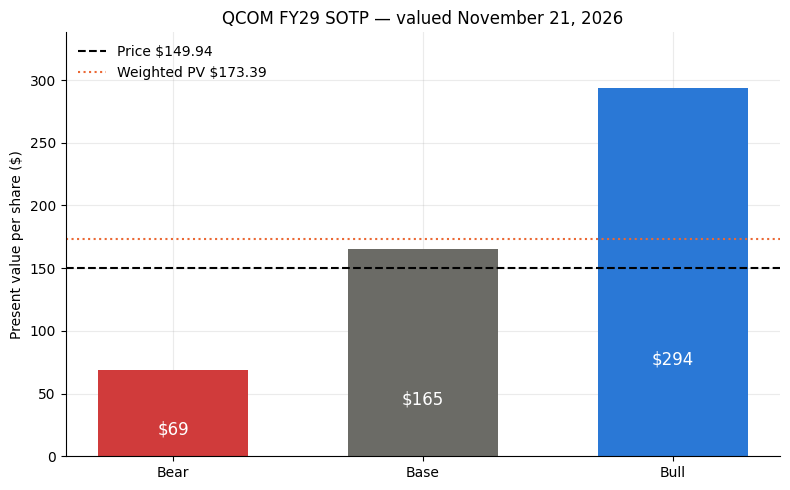

In [8]:
fig,ax=plt.subplots(figsize=(8,5))
bars=ax.bar(summary.index,summary.pv_price,color=[SCEN_COLORS[s] for s in summary.index],width=.6)
ax.axhline(m.CURRENT_PRICE,color='black',linestyle='--',label=f'Price ${m.CURRENT_PRICE:.2f}')
ax.axhline(blended,color='#eb6834',linestyle=':',label=f'Weighted PV ${blended:.2f}')
for b,v in zip(bars,summary.pv_price):
    ax.text(b.get_x()+b.get_width()/2,v*.25,f'${v:.0f}',ha='center',color='white',fontsize=12)
ax.set_ylim(0,summary.pv_price.max()*1.15)
ax.set_ylabel('Present value per share ($)'); ax.set_title(f'QCOM FY29 SOTP — valued {m.VALUATION_DATE}')
ax.legend(frameon=False,loc='upper left'); fig.tight_layout(); plt.show()

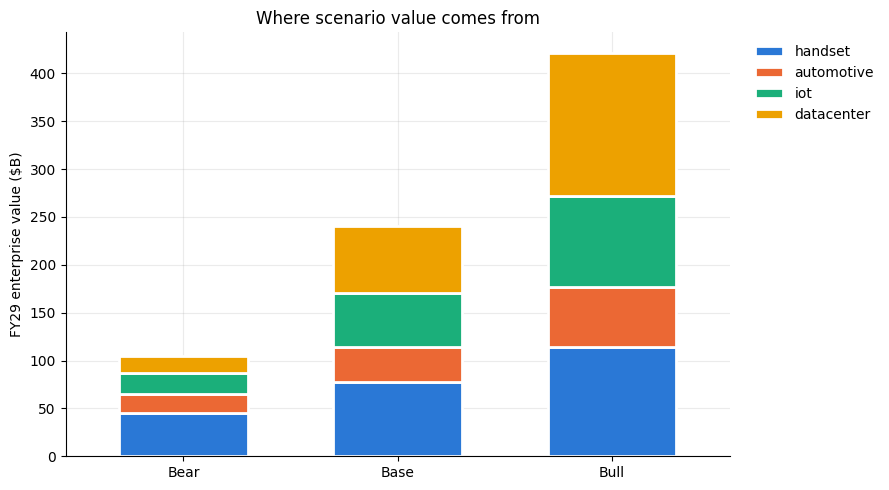

Data-center share of Base EV: 29.0%


In [9]:
ev_by_seg=pd.DataFrame({s:segment_table(s).set_index('segment')['EV $B'] for s in m.WEIGHTS}).T
ax=ev_by_seg.plot.bar(stacked=True,figsize=(9,5),width=.6,
    color=[SEG_COLORS[s] for s in ev_by_seg.columns],edgecolor='white',linewidth=2)
ax.set_ylabel('FY29 enterprise value ($B)'); ax.set_title('Where scenario value comes from')
ax.legend(bbox_to_anchor=(1.02,1),frameon=False); ax.tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.show()
print('Data-center share of Base EV:',f"{ev_by_seg.loc['Base','datacenter']/ev_by_seg.loc['Base'].sum():.1%}")

## 6. Sensitivity — Base discount rate and data-center exit multiple

In [10]:
rates=[.06,.08,.10,.12,.14]
mults=[8,12,16,18,22,26]
sensitivity=pd.DataFrame({f'{r:.0%}':[m.value_scenario('Base',discount_rate=r,
    datacenter_multiple=x)[1]['pv_price'] for x in mults] for r in rates},
    index=[f'{x}x' for x in mults])
print(sensitivity.to_string(float_format=lambda v:f'${v:.2f}'))

         6%      8%     10%     12%     14%
8x  $153.20 $145.23 $137.81 $130.89 $124.44
12x $165.44 $156.84 $148.82 $141.35 $134.38
16x $177.69 $168.44 $159.84 $151.81 $144.32
18x $183.81 $174.25 $165.34 $157.04 $149.30
22x $196.05 $185.85 $176.36 $167.50 $159.24
26x $208.29 $197.46 $187.37 $177.96 $169.18


## 7. EPS cross-check

Management's >$18 target is a lower-bound cross-check. The margins here are author
assumptions. The alternative valuation allocates EPS-implied total EBITDA by revenue
share, an illustration rather than a segment profitability forecast.

In [11]:
base=m.value_scenario('Base')[1]
required=m.eps_to_ebitda(m.MGMT_FY29_EPS)
print(f"Base EBITDA ${base['ebitda']:.3f}B; implied EPS ${m.ebitda_to_eps(base['ebitda']):.2f}")
print(f'Management EPS lower bound requires EBITDA ${required:.3f}B; '
      f"gap ${required-base['ebitda']:.3f}B ({1-base['ebitda']/required:.1%})")
print(f'Illustrative revenue-weighted EPS-target PV: ${m.management_eps_value():.2f}')
print('Sources:',m.REPORT_URL,m.CALL_URL,m.PRICE_URL,sep='\n')

Base EBITDA $20.735B; implied EPS $15.72
Management EPS lower bound requires EBITDA $23.403B; gap $2.668B (11.4%)
Illustrative revenue-weighted EPS-target PV: $197.94
Sources:
https://investor.qualcomm.com/files/content_files/FY2026-4th-Quarter-Earnings-Release.pdf
https://s204.q4cdn.com/645488518/files/content_files/Q4FY26-Earnings-Conference-Call_Transcript_11-5-26_Final.pdf
https://stockanalysis.com/stocks/qcom/history/
